In [1]:
import pandas as pd # bases de datos
import numpy as np # operaciones vectoriales
import seaborn as sns # gráficos
import matplotlib.pyplot as plt # gráficos
from datetime import datetime # variables fecha
from scipy import stats # pruebas de variables para selección
from itertools import combinations # posibles combinaciones para hacer interacciones cuantitativas y categóricas
from xgboost import XGBRegressor, XGBClassifier # selección de variables
import re # expresiones regulares - tratamiento en patrones de texto

from sklearn.linear_model import Ridge, Lasso, ElasticNet # 3 metodologías de regresión
from sklearn.metrics import make_scorer, mean_squared_error # métrica error
from sklearn import preprocessing  # procesamiento de datos
from sklearn.model_selection import train_test_split, GridSearchCV # dividir train y test - grilla para escoger el mejor modelo

import warnings # evitar logs
warnings.filterwarnings("ignore")

# XGBoost como clasificador porque Fraude es una variable binaria (0/1).
# Se pondera la clase minoritaria para reducir el efecto del desbalance.
def crear_xgb_selector(y):
    y_vector = np.asarray(y).reshape(-1)
    positivos = max(int(np.sum(y_vector == 1)), 1)
    negativos = int(np.sum(y_vector == 0))
    return XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=negativos / positivos,
        importance_type="gain",
        random_state=19042023,
        n_jobs=-1
    )


In [2]:
# candidatos para lambda
np.arange(0.1,10.1,0.1)

array([ 0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ,  1.1,
        1.2,  1.3,  1.4,  1.5,  1.6,  1.7,  1.8,  1.9,  2. ,  2.1,  2.2,
        2.3,  2.4,  2.5,  2.6,  2.7,  2.8,  2.9,  3. ,  3.1,  3.2,  3.3,
        3.4,  3.5,  3.6,  3.7,  3.8,  3.9,  4. ,  4.1,  4.2,  4.3,  4.4,
        4.5,  4.6,  4.7,  4.8,  4.9,  5. ,  5.1,  5.2,  5.3,  5.4,  5.5,
        5.6,  5.7,  5.8,  5.9,  6. ,  6.1,  6.2,  6.3,  6.4,  6.5,  6.6,
        6.7,  6.8,  6.9,  7. ,  7.1,  7.2,  7.3,  7.4,  7.5,  7.6,  7.7,
        7.8,  7.9,  8. ,  8.1,  8.2,  8.3,  8.4,  8.5,  8.6,  8.7,  8.8,
        8.9,  9. ,  9.1,  9.2,  9.3,  9.4,  9.5,  9.6,  9.7,  9.8,  9.9,
       10. ])

In [3]:
len(np.arange(0.1,10.1,0.1)) # cuantos modelos

100

In [4]:
import os

# Rutas relativas al notebook: los datos están en ../data y los envíos se guardan en ../submissions
path = os.path.join("..", "data")
ruta_salida = os.path.join("..", "submissions")
os.makedirs(ruta_salida, exist_ok=True)

In [5]:
%%time

df = pd.read_csv(path + '/train.csv', sep=';') # entrenamiento
prueba = pd.read_csv(path + '/test.csv', sep=';') # test

ct = ['Estado', 'Genero', 'Tipo_Tarjeta']

for k in ct:
    df[k] = df[k].astype("O")
    prueba[k] = prueba[k].astype("O")

# La selección de variables se hace solo con la partición de entrenamiento.
# Se usa la misma semilla y proporción de las funciones Ridge, Lasso y Elastic Net.
idx_entrenamiento_seleccion, idx_validacion_seleccion = train_test_split(
    df.index, test_size=0.5, random_state=19042023
)


CPU times: total: 875 ms
Wall time: 879 ms


In [6]:
prueba.get(ct).head(2)

,Estado,Genero,Tipo_Tarjeta
0,Alabama,Male,American Express
1,Alabama,Male,American Express


In [7]:
prueba.head()

,ID,Num_Tarjetas,Balance_Tj,Total_Transac,Trans_Int,Estado,Genero,Tipo_Tarjeta
0,9,1,2000,48,0,Alabama,Male,American Express
1,11,1,2000,5,4,Alabama,Male,American Express
2,19,1,541,21,9,Alabama,Male,American Express
3,20,1,408,44,0,Alabama,Male,American Express
4,22,1,0,5,0,Alabama,Male,American Express


In [8]:
df.shape # entrenamiento

(848548, 9)

In [9]:
prueba.shape # test

(200027, 8)

## Train

In [10]:
ft = pd.DataFrame(df.isnull().sum()).reset_index()
ft.columns = ["Variable","Faltantes"]
ft["% Faltantes"] = ft["Faltantes"] * 100 / df.shape[0]
ft.loc[ft["% Faltantes"]>0]

,Variable,Faltantes,% Faltantes


In [11]:
formato = pd.DataFrame({'Variable': list(df.columns), 'Formato': df.dtypes })
ft = pd.merge(ft,formato,on=["Variable"],how="left")
ft.head()

,Variable,Faltantes,% Faltantes,Formato
0,ID,0,0.0,int64
1,Num_Tarjetas,0,0.0,int64
2,Balance_Tj,0,0.0,int64
3,Total_Transac,0,0.0,int64
4,Trans_Int,0,0.0,int64


## Test

¿hay datos faltantes?

In [12]:
ft2 = pd.DataFrame(prueba.isnull().sum()).reset_index()
ft2.columns = ["Variable","Faltantes"]
ft2["% Faltantes"] = ft2["Faltantes"] * 100 / prueba.shape[0]
ft2.loc[ft2["% Faltantes"]>0]

,Variable,Faltantes,% Faltantes


## Análisis descriptivo

In [13]:
df.head(2)

,ID,Num_Tarjetas,Balance_Tj,Total_Transac,Trans_Int,Estado,Genero,Tipo_Tarjeta,Fraude
0,1,1,2000,31,9,Alabama,Male,American Express,0
1,2,1,0,25,0,Alabama,Male,American Express,0


In [14]:
# FEATURES vs target

cuantitativas = list(formato.loc[formato["Formato"]!="object", "Variable"])
cuantitativas = [x for x in cuantitativas if x not in ["ID", "Fraude"]]

cualitativas = list(formato.loc[formato["Formato"]=="object", "Variable"])
cualitativas = [x for x in cualitativas if x not in ["ID", "Fraude"]]


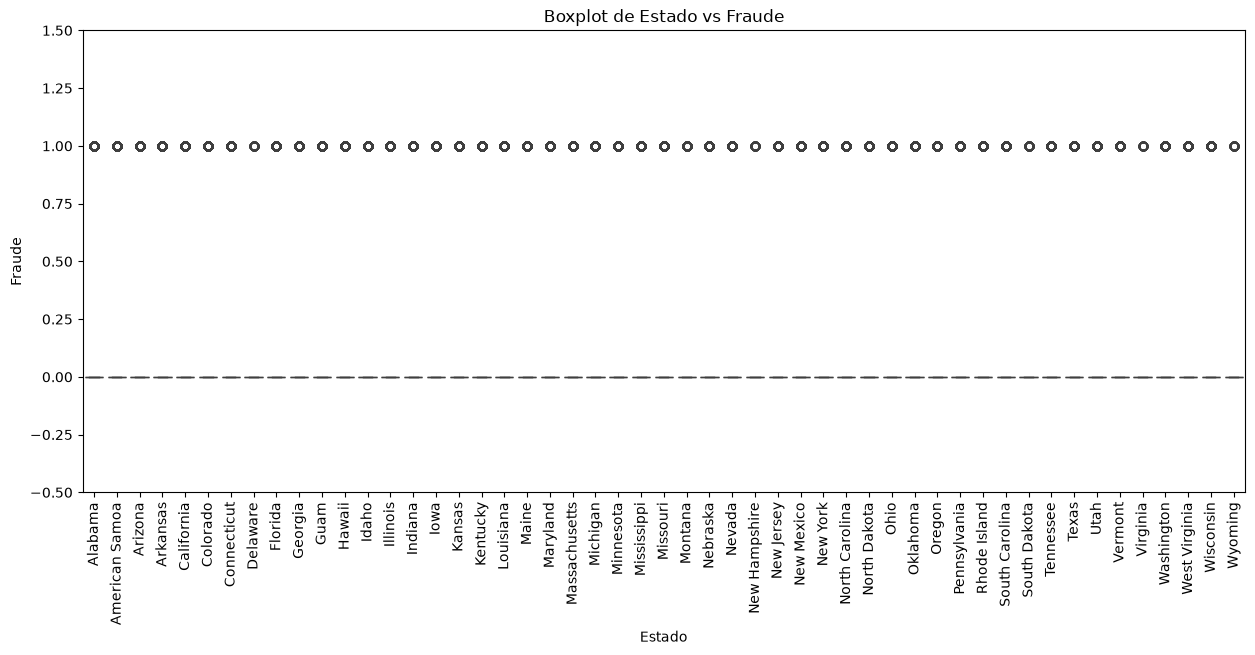

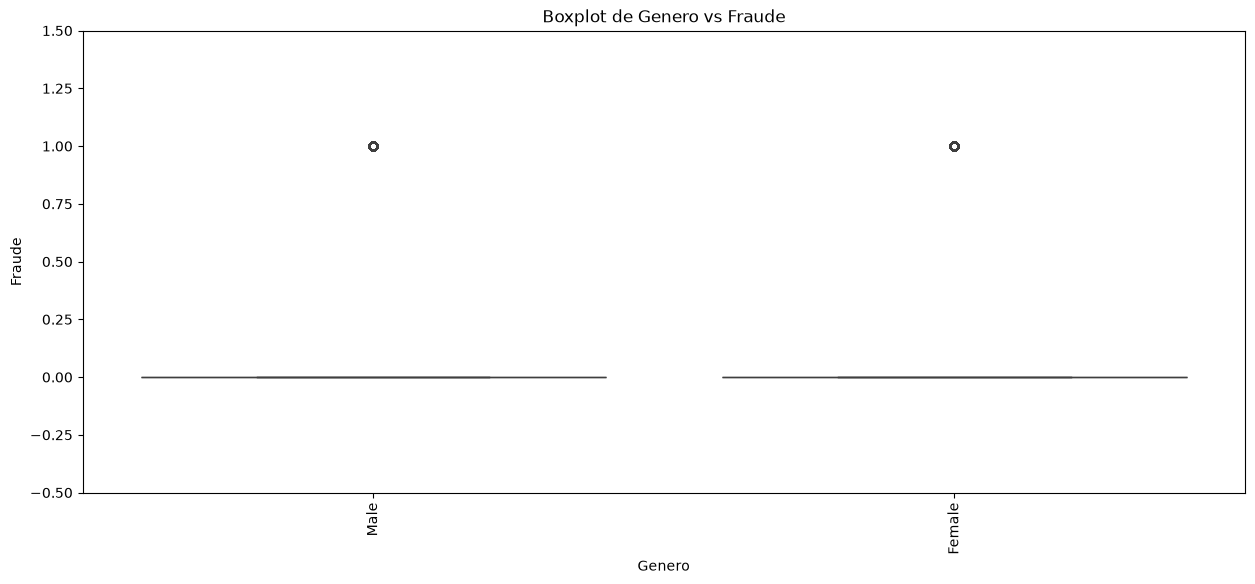

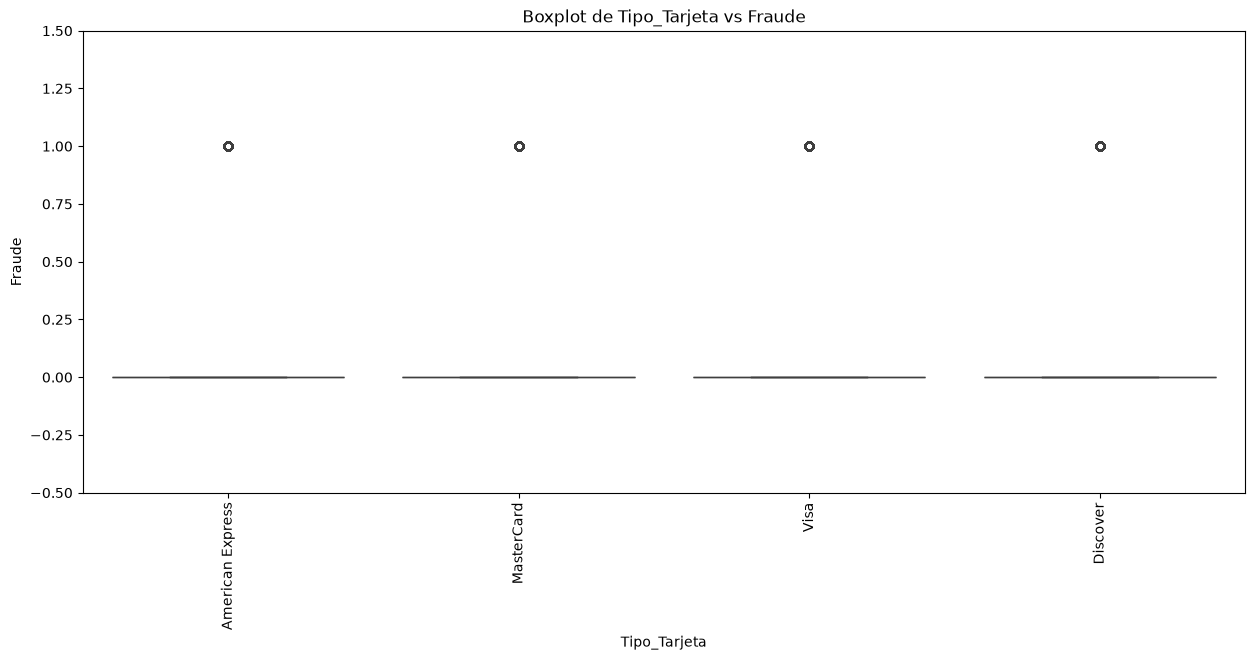

In [15]:
# Límites del eje Y para reducir el efecto de valores extremos
limite_inferior = -0.5
limite_superior = 1.5

for k in ct:
    # 1. Ensanchamos la figura (de 8 a 15) para que quepan más barras
    plt.figure(figsize=(15, 6))
    
    sns.boxplot(x=k, y="Fraude", data=df)
    
    # 2. Rotamos el texto del eje X 90 grados para que no se amontone
    plt.xticks(rotation=90)
    
    plt.ylim(limite_inferior, limite_superior)
    plt.title("Boxplot de " + k + " vs Fraude")
    
    plt.show()

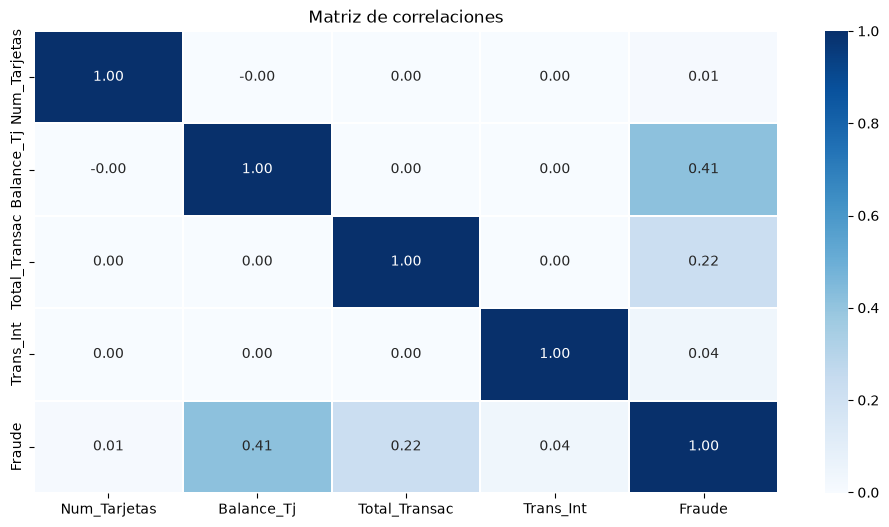

In [16]:
correlaciones = df.get(cuantitativas + ["Fraude"]).corr()
plt.figure(figsize=(12,6))
sns.heatmap(correlaciones, linewidths=0.01, cmap="Blues", annot=True, fmt=".2f")
plt.title("Matriz de correlaciones")
plt.show()

## Ingenierí­a de variables

### variables al cuadrado

In [17]:
df["Fraude"].describe()

count    848548.000000
mean          0.059852
std           0.237212
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           1.000000
Name: Fraude, dtype: float64

In [18]:
base_cuadrado = df[cuantitativas].copy()
base_cuadrado["Fraude"] = df["Fraude"].copy()

var_names2, correlaciones = [], []

for k in cuantitativas:
    base_cuadrado[k + "_2"] = base_cuadrado[k] ** 2

    # Calcular correlación de la variable al cuadrado con Fraude
    corr = base_cuadrado[[k + "_2", "Fraude"]].corr().iloc[0, 1]
    
    # Guardar correlación y variable
    var_names2.append(k + "_2")
    correlaciones.append(np.round(corr, 2))

In [19]:
pcuadrado1 = pd.DataFrame({'Variable2':var_names2,'correlacion':correlaciones})
pcuadrado1['criterio'] = pcuadrado1['correlacion'].apply(lambda x: 1 if abs(x) > 0.5 else 0)
pcuadrado1.loc[pcuadrado1["criterio"]==1,].head(10)

,Variable2,correlacion,criterio


## Interacciones cuantitativas

In [20]:
list(combinations(cuantitativas,2))

[('Num_Tarjetas', 'Balance_Tj'),
 ('Num_Tarjetas', 'Total_Transac'),
 ('Num_Tarjetas', 'Trans_Int'),
 ('Balance_Tj', 'Total_Transac'),
 ('Balance_Tj', 'Trans_Int'),
 ('Total_Transac', 'Trans_Int')]

In [21]:
len(list(combinations(cuantitativas,2)))

6

In [22]:
lista_inter = list(combinations(cuantitativas,2))
base_interacciones = df.get(cuantitativas).copy()
base_interacciones["Fraude"] = df["Fraude"].copy()

var_interaccion, correlaciones = [], []
for k in lista_inter:
    col_name = k[0] + "__" + k[1]
    base_interacciones[col_name] = base_interacciones[k[0]] * base_interacciones[k[1]]

    corr = base_interacciones[[col_name, "Fraude"]].corr().iloc[0, 1]
    var_interaccion.append(col_name)
    correlaciones.append(np.round(corr, 2))

pxy = pd.DataFrame({'Variable':var_interaccion, 'correlacion':correlaciones})
pxy['criterio'] = pxy['correlacion'].apply(lambda x: 1 if abs(x) > 0.5 else 0)
pxy = pxy.sort_values('correlacion', ascending=False).reset_index(drop=True)
pxy.head()

,Variable,correlacion,criterio
0,Balance_Tj__Total_Transac,0.48,0
1,Num_Tarjetas__Balance_Tj,0.41,0
2,Num_Tarjetas__Total_Transac,0.22,0
3,Balance_Tj__Trans_Int,0.18,0
4,Total_Transac__Trans_Int,0.11,0


In [23]:
list(pxy["Variable"])

['Balance_Tj__Total_Transac',
 'Num_Tarjetas__Balance_Tj',
 'Num_Tarjetas__Total_Transac',
 'Balance_Tj__Trans_Int',
 'Total_Transac__Trans_Int',
 'Num_Tarjetas__Trans_Int']

## Razones

In [24]:
raz1 = [(x, y) for x in cuantitativas for y in cuantitativas]
base_razones1 = df[cuantitativas].copy()
base_razones1["Fraude"] = df["Fraude"].copy()

var_nm, correlaciones = [], []
for j in raz1:
    if j[0] != j[1]:
        nombre_var = j[0] + "__coc__" + j[1]
        base_razones1[nombre_var] = base_razones1[j[0]] / (base_razones1[j[1]] + 0.01)

        corr = base_razones1[[nombre_var, "Fraude"]].corr().iloc[0, 1]

        var_nm.append(nombre_var)
        correlaciones.append(np.round(corr, 2))

In [25]:
prazones = pd.DataFrame({'Variable': var_nm, 'correlacion': correlaciones})
prazones['criterio'] = prazones['correlacion'].apply(lambda x: 1 if abs(x) > 0.5 else 0)
prazones_filtrado = prazones.iloc[(prazones['criterio'] == 1).to_numpy()]
prazones_filtrado.head()

,Variable,correlacion,criterio


## Interacciones categóricas

In [26]:
df.head(2)

,ID,Num_Tarjetas,Balance_Tj,Total_Transac,Trans_Int,Estado,Genero,Tipo_Tarjeta,Fraude
0,1,1,2000,31,9,Alabama,Male,American Express,0
1,2,1,0,25,0,Alabama,Male,American Express,0


In [27]:
categoricas = list(formato.loc[formato["Formato"] == "object", "Variable"])
categoricas = [x for x in categoricas if x not in ["ID", "id", "Target", "Fraude"]]

def nombre_(x):
    return "C" + str(x)

categoricas


['Estado', 'Genero', 'Tipo_Tarjeta']

In [28]:
list(combinations(categoricas,2))

[('Estado', 'Genero'), ('Estado', 'Tipo_Tarjeta'), ('Genero', 'Tipo_Tarjeta')]

In [29]:
cb = list(combinations(categoricas, 2))
p_value, modalidades, nombre_var = [], [], []

# Solo se usa la partición de entrenamiento para filtrar interacciones categóricas.
base2 = df.loc[idx_entrenamiento_seleccion, categoricas + ["Fraude"]].copy()

for k in categoricas:
    base2[k] = base2[k].apply(nombre_)

for col1, col2 in cb:
    nombre_interaccion = col1 + "__" + col2
    base2[nombre_interaccion] = base2[col1] + "__" + base2[col2]

    grupos = base2.groupby(nombre_interaccion)["Fraude"].apply(lambda x: x.dropna().to_numpy())
    mods = grupos.index.tolist()
    pares_mods = list(combinations(mods, 2))
    pvals_mods = []

    for par in pares_mods:
        m1 = grupos[par[0]]
        m2 = grupos[par[1]]
        if len(m1) > 0 and len(m2) > 0:
            pv = stats.kruskal(m1, m2)[1]
            pvals_mods.append(pv)

    pv_min = np.min(pvals_mods) if len(pvals_mods) > 0 else np.nan
    nombre_var.append(nombre_interaccion)
    modalidades.append(len(mods))
    p_value.append(pv_min)

print("Cálculo de interacciones categóricas terminado con la partición de entrenamiento.")


Cálculo de interacciones categóricas terminado con la partición de entrenamiento.


In [30]:
pc = pd.DataFrame({'Variable':nombre_var,'Num Modalidades':modalidades,'p value':p_value})
pc.loc[(pc["p value"]<=0.20) & (pc["Num Modalidades"]<=15),].sort_values(["p value"],ascending=True).head()

,Variable,Num Modalidades,p value
2,Genero__Tipo_Tarjeta,8,8.599749e-229


## Dummies categóricas más significativas (p value <= 0.20 y bajo número de modalidades)

In [31]:
seleccion1 = list(pc.loc[(pc["p value"]<=0.20) & (pc["Num Modalidades"]<=15), "Variable"])
sel1 = base2.get(seleccion1)

mapa_cat_interacciones = {}
bloques_cat_interacciones = []

for k in seleccion1:
    col1, col2 = k.split("__", 1)
    dummies = pd.get_dummies(sel1[k], drop_first=True, dtype=np.int8)

    for nivel in dummies.columns:
        nombre_columna = k + "_" + str(nivel)
        bloques_cat_interacciones.append(dummies[nivel].rename(nombre_columna))
        mapa_cat_interacciones[nombre_columna] = (col1, col2, nivel)

if bloques_cat_interacciones:
    lb1 = pd.concat(bloques_cat_interacciones, axis=1)
else:
    lb1 = pd.DataFrame(index=base2.index)

lb1["Fraude"] = base2["Fraude"].copy()
lb1.head(3)


,Genero__Tipo_Tarjeta_CFemale__CDiscover,Genero__Tipo_Tarjeta_CFemale__CMasterCard,Genero__Tipo_Tarjeta_CFemale__CVisa,Genero__Tipo_Tarjeta_CMale__CAmerican Express,Genero__Tipo_Tarjeta_CMale__CDiscover,Genero__Tipo_Tarjeta_CMale__CMasterCard,Genero__Tipo_Tarjeta_CMale__CVisa,Fraude
110374,0,0,0,1,0,0,0,1
223042,0,1,0,0,0,0,0,0
841130,0,0,0,1,0,0,0,0


## Interacción cuantitativa vs categórica

In [32]:
cat_cuanti = [(x,y) for x in cuantitativas for y in categoricas]
cat_cuanti[0]

('Num_Tarjetas', 'Estado')

In [33]:
v1, v2, correlaciones_max = [], [], []
base_correlacion = df.loc[idx_entrenamiento_seleccion]

for j in cat_cuanti:
    k1, k2 = j
    dummies = pd.get_dummies(base_correlacion[k2])
    correlaciones_c = []

    for nivel in dummies.columns:
        interaccion = dummies[nivel].astype(np.float32) * base_correlacion[k1].astype(np.float32)
        corr = pd.concat([interaccion.rename("interaccion"), base_correlacion["Fraude"]], axis=1).corr().iloc[0, 1]
        correlaciones_c.append(np.round(corr, 2))

    max_ = np.max(np.abs(correlaciones_c)) if correlaciones_c else 0
    v1.append(k1)
    v2.append(k2)
    correlaciones_max.append(np.round(max_, 2))


In [34]:
pc2 = pd.DataFrame({'Cuantitativa': v1, 'Categórica': v2, 'correlacion': correlaciones_max})
# Este cuadro queda como diagnóstico. La selección de interacciones ya no depende del umbral 0.5.
pc2.sort_values("correlacion", ascending=False).head()


,Cuantitativa,Categórica,correlacion
4,Balance_Tj,Genero,0.24
5,Balance_Tj,Tipo_Tarjeta,0.20
7,Total_Transac,Genero,0.15
3,Balance_Tj,Estado,0.14
8,Total_Transac,Tipo_Tarjeta,0.12


## Base de Feature Enginnering

In [35]:
# Generar todas las interacciones cuantitativa-categórica candidatas.
# XGBoost las evaluará junto con los efectos principales y las ordenará por importancia.
df_seleccion = df.loc[idx_entrenamiento_seleccion].copy()

# Conservar los niveles observados en entrenamiento y usar el primero como referencia.
niveles_categoricas_interacciones = {
    cat: sorted(df_seleccion[cat].dropna().unique().tolist(), key=lambda x: str(x))
    for cat in categoricas
}

X5_principales_categoricas = pd.DataFrame(index=df_seleccion.index)
for cat in categoricas:
    niveles = niveles_categoricas_interacciones[cat]
    for nivel in niveles[1:]:
        X5_principales_categoricas[f"{cat}__{nivel}"] = df_seleccion[cat].eq(nivel).astype(np.int8)

X5_principales = pd.concat(
    [df_seleccion[cuantitativas].astype(np.float32), X5_principales_categoricas],
    axis=1
)

mapa_interacciones_cuant_cat = {}
bloques_interacciones = []

for cuant in cuantitativas:
    for cat in categoricas:
        niveles = niveles_categoricas_interacciones[cat]
        # La categoría de referencia queda representada por el efecto principal cuantitativo.
        for nivel in niveles[1:]:
            nombre = f"{cuant}__{cat}__nivel_{nivel}"
            serie = (
                df_seleccion[cuant].astype(np.float32)
                * df_seleccion[cat].eq(nivel).astype(np.float32)
            ).rename(nombre)
            bloques_interacciones.append(serie)
            mapa_interacciones_cuant_cat[nombre] = (cuant, cat, nivel)

if bloques_interacciones:
    X_interacciones = pd.concat(bloques_interacciones, axis=1)
else:
    X_interacciones = pd.DataFrame(index=df_seleccion.index)

interacciones_candidatas = list(X_interacciones.columns)
X5 = pd.concat([X5_principales, X_interacciones], axis=1)
y5 = df_seleccion["Fraude"].astype(int)

# g1 se conserva como vista de las interacciones candidatas, para inspección.
g1 = X_interacciones.copy()
g1["Fraude"] = y5


In [36]:
print("Número de interacciones cuantitativa-categórica candidatas:", len(interacciones_candidatas))
print("Filas usadas para la selección:", len(df_seleccion))
print("El umbral de correlación 0.5 no se usa para descartar candidatas.")


Número de interacciones cuantitativa-categórica candidatas: 216
Filas usadas para la selección: 424274
El umbral de correlación 0.5 no se usa para descartar candidatas.


## Selección de variables con XGBOOST

### variables al cuadrado

In [37]:
pcuadrado1.head()

,Variable2,correlacion,criterio
0,Num_Tarjetas_2,0.01,0
1,Balance_Tj_2,0.49,0
2,Total_Transac_2,0.23,0
3,Trans_Int_2,0.04,0


In [38]:
var_cuad = list(pcuadrado1["Variable2"])
base_modelo1 = base_cuadrado.get(var_cuad+["Fraude"])
base_modelo1.head()

,Num_Tarjetas_2,Balance_Tj_2,Total_Transac_2,Trans_Int_2,Fraude
0,1,4000000,961,81,0
1,1,0,625,0,0
2,1,4000000,6084,9,0
3,1,4000000,121,0,0
4,1,4000000,1600,0,0


In [39]:
cov = [x for x in base_modelo1.columns if x != "Fraude"]
X1 = base_modelo1.loc[idx_entrenamiento_seleccion, cov]
y1 = base_modelo1.loc[idx_entrenamiento_seleccion, ["Fraude"]]

modelo1 = crear_xgb_selector(y1)
modelo1 = modelo1.fit(X1, y1.to_numpy().ravel())

importancias = modelo1.feature_importances_
imp1 = pd.DataFrame({'Variable': X1.columns, 'Importancia': importancias})
if imp1["Importancia"].sum() > 0:
    imp1["Importancia"] = imp1["Importancia"] * 100 / imp1["Importancia"].sum()
imp1 = imp1.sort_values(["Importancia"], ascending=False).reset_index(drop=True)
imp1.head()


,Variable,Importancia
0,Balance_Tj_2,60.817738
1,Total_Transac_2,35.772354
2,Trans_Int_2,2.329258
3,Num_Tarjetas_2,1.080649


## Interacciones cuantitativas

In [40]:
pxy.head()

,Variable,correlacion,criterio
0,Balance_Tj__Total_Transac,0.48,0
1,Num_Tarjetas__Balance_Tj,0.41,0
2,Num_Tarjetas__Total_Transac,0.22,0
3,Balance_Tj__Trans_Int,0.18,0
4,Total_Transac__Trans_Int,0.11,0


In [41]:
pxy["criterio"].value_counts()

criterio
0    6
Name: count, dtype: int64

In [42]:
var_int = list(pxy["Variable"])
base_modelo2 = base_interacciones.get(var_int+["Fraude"])
base_modelo2.head()

,Balance_Tj__Total_Transac,Num_Tarjetas__Balance_Tj,Num_Tarjetas__Total_Transac,Balance_Tj__Trans_Int,Total_Transac__Trans_Int,Num_Tarjetas__Trans_Int,Fraude
0,62000,2000,31,18000,279,9,0
1,0,0,25,0,0,0,0
2,156000,2000,78,6000,234,3,0
3,22000,2000,11,0,0,0,0
4,80000,2000,40,0,0,0,0


In [43]:
cov = [x for x in base_modelo2.columns if x != "Fraude"]
X2 = base_modelo2.loc[idx_entrenamiento_seleccion, cov]
y2 = base_modelo2.loc[idx_entrenamiento_seleccion, ["Fraude"]]

modelo2 = crear_xgb_selector(y2)
modelo2 = modelo2.fit(X2, y2.to_numpy().ravel())

importancias = modelo2.feature_importances_
imp2 = pd.DataFrame({'Variable': X2.columns, 'Importancia': importancias})
if imp2["Importancia"].sum() > 0:
    imp2["Importancia"] = imp2["Importancia"] * 100 / imp2["Importancia"].sum()
imp2 = imp2.sort_values(["Importancia"], ascending=False).reset_index(drop=True)
imp2.head()


,Variable,Importancia
0,Balance_Tj__Total_Transac,43.387161
1,Num_Tarjetas__Balance_Tj,32.717129
2,Num_Tarjetas__Total_Transac,17.161270
3,Total_Transac__Trans_Int,3.195199
4,Balance_Tj__Trans_Int,2.699080


### Razones

In [44]:
prazones.head()

,Variable,correlacion,criterio
0,Num_Tarjetas__coc__Balance_Tj,-0.13,0
1,Num_Tarjetas__coc__Total_Transac,-0.01,0
2,Num_Tarjetas__coc__Trans_Int,-0.02,0
3,Balance_Tj__coc__Num_Tarjetas,0.41,0
4,Balance_Tj__coc__Total_Transac,0.00,0


In [45]:
var_raz = list(prazones["Variable"])
base_modelo3 = base_razones1.get(var_raz+["Fraude"])
base_modelo3.head()

,Num_Tarjetas__coc__Balance_Tj,Num_Tarjetas__coc__Total_Transac,Num_Tarjetas__coc__Trans_Int,Balance_Tj__coc__Num_Tarjetas,Balance_Tj__coc__Total_Transac,Balance_Tj__coc__Trans_Int,Total_Transac__coc__Num_Tarjetas,Total_Transac__coc__Balance_Tj,Total_Transac__coc__Trans_Int,Trans_Int__coc__Num_Tarjetas,Trans_Int__coc__Balance_Tj,Trans_Int__coc__Total_Transac,Fraude
0,0.0005,0.032248,0.110988,1980.19802,64.495324,221.975583,30.693069,0.0155,3.440622,8.910891,0.0045,0.290229,0
1,100.0000,0.039984,100.000000,0.00000,0.000000,0.000000,24.752475,2500.0000,2500.000000,0.000000,0.0000,0.000000,0
2,0.0005,0.012819,0.332226,1980.19802,25.637739,664.451827,77.227723,0.0390,25.913621,2.970297,0.0015,0.038457,0
3,0.0005,0.090827,100.000000,1980.19802,181.653043,200000.000000,10.891089,0.0055,1100.000000,0.000000,0.0000,0.000000,0
4,0.0005,0.024994,100.000000,1980.19802,49.987503,200000.000000,39.603960,0.0200,4000.000000,0.000000,0.0000,0.000000,0


In [46]:
cov = [x for x in base_modelo3.columns if x != "Fraude"]
X3 = base_modelo3.loc[idx_entrenamiento_seleccion, cov]
y3 = base_modelo3.loc[idx_entrenamiento_seleccion, ["Fraude"]]

modelo3 = crear_xgb_selector(y3)
modelo3 = modelo3.fit(X3, y3.to_numpy().ravel())

importancias = modelo3.feature_importances_
imp3 = pd.DataFrame({'Variable': X3.columns, 'Importancia': importancias})
if imp3["Importancia"].sum() > 0:
    imp3["Importancia"] = imp3["Importancia"] * 100 / imp3["Importancia"].sum()
imp3 = imp3.sort_values(["Importancia"], ascending=False).reset_index(drop=True)
imp3.head()


,Variable,Importancia
0,Balance_Tj__coc__Num_Tarjetas,21.444588
1,Total_Transac__coc__Num_Tarjetas,20.145168
2,Num_Tarjetas__coc__Balance_Tj,14.261561
3,Balance_Tj__coc__Trans_Int,12.798520
4,Num_Tarjetas__coc__Total_Transac,8.531548


## Interacciones categóricas

In [47]:
pc.head()

,Variable,Num Modalidades,p value
0,Estado__Genero,102,1.859965e-72
1,Estado__Tipo_Tarjeta,204,1.483073e-63
2,Genero__Tipo_Tarjeta,8,8.599749e-229


In [48]:
lb1.head()

,Genero__Tipo_Tarjeta_CFemale__CDiscover,Genero__Tipo_Tarjeta_CFemale__CMasterCard,Genero__Tipo_Tarjeta_CFemale__CVisa,Genero__Tipo_Tarjeta_CMale__CAmerican Express,Genero__Tipo_Tarjeta_CMale__CDiscover,Genero__Tipo_Tarjeta_CMale__CMasterCard,Genero__Tipo_Tarjeta_CMale__CVisa,Fraude
110374,0,0,0,1,0,0,0,1
223042,0,1,0,0,0,0,0,0
841130,0,0,0,1,0,0,0,0
672724,0,0,0,0,0,1,0,1
818420,0,0,0,0,0,1,0,0


In [49]:
cov = [x for x in lb1.columns if x != "Fraude"]
X4 = lb1[cov]
y4 = lb1[["Fraude"]]

if len(cov) > 0:
    modelo4 = crear_xgb_selector(y4)
    modelo4 = modelo4.fit(X4, y4.to_numpy().ravel())
    importancias = modelo4.feature_importances_
    imp4 = pd.DataFrame({'Variable': X4.columns, 'Importancia': importancias})
    if imp4["Importancia"].sum() > 0:
        imp4["Importancia"] = imp4["Importancia"] * 100 / imp4["Importancia"].sum()
    imp4 = imp4.sort_values(["Importancia"], ascending=False).reset_index(drop=True)
else:
    imp4 = pd.DataFrame(columns=["Variable", "Importancia"])

imp4.head(5)


,Variable,Importancia
0,Genero__Tipo_Tarjeta_CMale__CMasterCard,54.026306
1,Genero__Tipo_Tarjeta_CFemale__CVisa,22.138647
2,Genero__Tipo_Tarjeta_CMale__CAmerican Express,8.170910
3,Genero__Tipo_Tarjeta_CFemale__CDiscover,7.172421
4,Genero__Tipo_Tarjeta_CFemale__CMasterCard,3.872273


## Interacción cuantitativa - categórica

Se generan todas las candidatas (sin filtrar por correlación 0.5). XGBoost las evalúa junto con los efectos principales y elige las de mayor importancia usando solo la partición de entrenamiento.


In [50]:
g1.head()

,Num_Tarjetas__Estado__nivel_American Samoa,Num_Tarjetas__Estado__nivel_Arizona,Num_Tarjetas__Estado__nivel_Arkansas,Num_Tarjetas__Estado__nivel_California,Num_Tarjetas__Estado__nivel_Colorado,Num_Tarjetas__Estado__nivel_Connecticut,Num_Tarjetas__Estado__nivel_Delaware,Num_Tarjetas__Estado__nivel_Florida,Num_Tarjetas__Estado__nivel_Georgia,Num_Tarjetas__Estado__nivel_Guam,...,Trans_Int__Estado__nivel_Virginia,Trans_Int__Estado__nivel_Washington,Trans_Int__Estado__nivel_West Virginia,Trans_Int__Estado__nivel_Wisconsin,Trans_Int__Estado__nivel_Wyoming,Trans_Int__Genero__nivel_Male,Trans_Int__Tipo_Tarjeta__nivel_Discover,Trans_Int__Tipo_Tarjeta__nivel_MasterCard,Trans_Int__Tipo_Tarjeta__nivel_Visa,Fraude
110374,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
223042,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
841130,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,57.0,0.0,0.0,57.0,0.0,0.0,0.0,0
672724,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,42.0,0.0,42.0,0.0,1
818420,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,10.0,0.0,0.0,0.0,10.0,0.0,10.0,0.0,0


In [51]:
# Entrenar XGBoost con efectos principales + todas las interacciones candidatas.
# Luego conservar la importancia de las columnas de interacción, no la de efectos principales.
modelo5 = crear_xgb_selector(y5)
modelo5 = modelo5.fit(X5, y5.to_numpy().ravel())

imp5 = pd.DataFrame({
    "Variable": X5.columns,
    "Importancia": modelo5.feature_importances_
})
imp5 = imp5.loc[imp5["Variable"].isin(interacciones_candidatas)].copy()

if imp5["Importancia"].sum() > 0:
    imp5["Importancia"] = imp5["Importancia"] * 100 / imp5["Importancia"].sum()

imp5 = imp5.sort_values("Importancia", ascending=False).reset_index(drop=True)
imp5.head(10)


,Variable,Importancia
0,Balance_Tj__Genero__nivel_Male,9.529754
1,Balance_Tj__Tipo_Tarjeta__nivel_Visa,9.451994
2,Balance_Tj__Tipo_Tarjeta__nivel_MasterCard,9.238464
3,Total_Transac__Genero__nivel_Male,8.346776
4,Balance_Tj__Estado__nivel_California,4.829849
5,Total_Transac__Tipo_Tarjeta__nivel_MasterCard,4.239223
6,Total_Transac__Tipo_Tarjeta__nivel_Visa,3.886237
7,Total_Transac__Estado__nivel_California,3.103010
8,Balance_Tj__Estado__nivel_Guam,2.068114
9,Num_Tarjetas__Tipo_Tarjeta__nivel_MasterCard,2.034100


## Variables más importantes

Las importancias se calcularon en la partición de entrenamiento para evitar utilizar la validación en la selección.


In [52]:
c2 = list(imp1.iloc[0:3,0]) # Variables al cuadrado
c2

['Balance_Tj_2', 'Total_Transac_2', 'Trans_Int_2']

In [53]:
cxy = list(imp2.iloc[0:3,0]) # Interacciones cuantitativas
cxy

['Balance_Tj__Total_Transac',
 'Num_Tarjetas__Balance_Tj',
 'Num_Tarjetas__Total_Transac']

In [54]:
razxy = list(imp3.iloc[0:3,0]) # Razones
razxy

['Balance_Tj__coc__Num_Tarjetas',
 'Total_Transac__coc__Num_Tarjetas',
 'Num_Tarjetas__coc__Balance_Tj']

In [55]:
catxy = list(imp4.iloc[0:3,0]) # Interacciones categóricas
catxy

['Genero__Tipo_Tarjeta_CMale__CMasterCard',
 'Genero__Tipo_Tarjeta_CFemale__CVisa',
 'Genero__Tipo_Tarjeta_CMale__CAmerican Express']

In [56]:
# Seleccionar hasta las tres interacciones con importancia positiva.
# Si XGBoost no encuentra utilidad predictiva en ninguna, la lista puede quedar vacía.
cuactxy = imp5.loc[imp5["Importancia"] > 0, "Variable"].head(3).tolist()
cuactxy


['Balance_Tj__Genero__nivel_Male',
 'Balance_Tj__Tipo_Tarjeta__nivel_Visa',
 'Balance_Tj__Tipo_Tarjeta__nivel_MasterCard']

## Preparación de datos

In [57]:
# Construcción consistente de la base para entrenamiento y test.
# Los nombres seleccionados se reconstruyen a partir de los mapas creados en las celdas anteriores.
def construir_base_modelo(datos, incluir_objetivo=False):
    D1 = datos[cuantitativas].copy()

    # Variables al cuadrado seleccionadas por XGBoost.
    for item in c2:
        origen = item.rsplit("_", 1)[0]
        D1[item] = datos[origen] ** 2

    # Interacciones cuantitativas seleccionadas por XGBoost.
    for item in cxy:
        col1, col2 = item.split("__", 1)
        D1[item] = datos[col1] * datos[col2]

    # Razones seleccionadas por XGBoost.
    for item in razxy:
        col1, col2 = item.split("__coc__", 1)
        D1[item] = datos[col1] / (datos[col2] + 0.01)

    # Efectos principales categóricos, con la misma referencia de entrenamiento.
    D_categoricas = pd.DataFrame(index=datos.index)
    for cat in categoricas:
        niveles = niveles_categoricas_interacciones.get(cat, [])
        for nivel in niveles[1:]:
            D_categoricas[f"{cat}__{nivel}"] = datos[cat].eq(nivel).astype(np.int8)

    # Interacciones categóricas seleccionadas: reconstruir la modalidad exacta, sin regex.
    D_cat_interacciones = pd.DataFrame(index=datos.index)
    for item in catxy:
        if item in mapa_cat_interacciones:
            col1, col2, nivel = mapa_cat_interacciones[item]
            combinacion = (
                datos[col1].map(nombre_).astype(str)
                + "__"
                + datos[col2].map(nombre_).astype(str)
            )
            D_cat_interacciones[item] = combinacion.eq(nivel).astype(np.int8)

    # Interacciones cuantitativa-categóricas elegidas entre todas las candidatas.
    D_quant_cat = pd.DataFrame(index=datos.index)
    for item in cuactxy:
        cuant, cat, nivel = mapa_interacciones_cuant_cat[item]
        D_quant_cat[item] = (
            datos[cuant].astype(np.float32)
            * datos[cat].eq(nivel).astype(np.float32)
        )

    base = pd.concat(
        [D1, D_categoricas, D_cat_interacciones, D_quant_cat],
        axis=1
    )
    base = base.loc[:, ~base.columns.duplicated()]

    if incluir_objetivo and "Fraude" in datos.columns:
        base["Fraude"] = datos["Fraude"].copy()

    return base

base_modelo = construir_base_modelo(df, incluir_objetivo=True)
columnas_predictoras_modelo = [c for c in base_modelo.columns if c != "Fraude"]
base_modelo.head(3)


,Num_Tarjetas,Balance_Tj,Total_Transac,Trans_Int,Balance_Tj_2,Total_Transac_2,Trans_Int_2,Balance_Tj__Total_Transac,Num_Tarjetas__Balance_Tj,Num_Tarjetas__Total_Transac,...,Tipo_Tarjeta__Discover,Tipo_Tarjeta__MasterCard,Tipo_Tarjeta__Visa,Genero__Tipo_Tarjeta_CMale__CMasterCard,Genero__Tipo_Tarjeta_CFemale__CVisa,Genero__Tipo_Tarjeta_CMale__CAmerican Express,Balance_Tj__Genero__nivel_Male,Balance_Tj__Tipo_Tarjeta__nivel_Visa,Balance_Tj__Tipo_Tarjeta__nivel_MasterCard,Fraude
0,1,2000,31,9,4000000,961,81,62000,2000,31,...,0,0,0,0,0,1,2000.0,0.0,0.0,0
1,1,0,25,0,0,625,0,0,0,25,...,0,0,0,0,0,1,0.0,0.0,0.0,0
2,1,2000,78,3,4000000,6084,9,156000,2000,78,...,0,0,0,0,0,1,2000.0,0.0,0.0,0


## Base modelo

In [58]:
print("Dimensiones de base_modelo:", base_modelo.shape)
print("Número de predictores:", len(columnas_predictoras_modelo))
base_modelo.head(3)


Dimensiones de base_modelo: (848548, 74)
Número de predictores: 73


,Num_Tarjetas,Balance_Tj,Total_Transac,Trans_Int,Balance_Tj_2,Total_Transac_2,Trans_Int_2,Balance_Tj__Total_Transac,Num_Tarjetas__Balance_Tj,Num_Tarjetas__Total_Transac,...,Tipo_Tarjeta__Discover,Tipo_Tarjeta__MasterCard,Tipo_Tarjeta__Visa,Genero__Tipo_Tarjeta_CMale__CMasterCard,Genero__Tipo_Tarjeta_CFemale__CVisa,Genero__Tipo_Tarjeta_CMale__CAmerican Express,Balance_Tj__Genero__nivel_Male,Balance_Tj__Tipo_Tarjeta__nivel_Visa,Balance_Tj__Tipo_Tarjeta__nivel_MasterCard,Fraude
0,1,2000,31,9,4000000,961,81,62000,2000,31,...,0,0,0,0,0,1,2000.0,0.0,0.0,0
1,1,0,25,0,0,625,0,0,0,25,...,0,0,0,0,0,1,0.0,0.0,0.0,0
2,1,2000,78,3,4000000,6084,9,156000,2000,78,...,0,0,0,0,0,1,2000.0,0.0,0.0,0


In [59]:
formatos_ = pd.DataFrame(base_modelo.dtypes)
formatos_.loc[formatos_[0]=="O",]

,0


In [60]:
# Verificar que la matriz final de Ridge, Lasso y Elastic Net sea numérica.
columnas_object = base_modelo.drop(columns=["Fraude"]).select_dtypes(include=["object", "category"]).columns.tolist()
if columnas_object:
    raise ValueError(f"Hay predictores no numéricos que deben codificarse: {columnas_object}")
print("Todos los predictores de base_modelo son numéricos.")


Todos los predictores de base_modelo son numéricos.


## Continuación siguiente clase

## Modelado orientado a ROC-AUC

En esta sección se evalúan los modelos con la métrica solicitada por la competencia: **ROC-AUC**. Se conserva la comparación entre Ridge, Lasso y Elastic Net como regresores que producen puntuaciones continuas, y se añade XGBoost como clasificador de referencia.

Para que la validación sea más confiable, esta evaluación parte de las variables originales y de unas pocas variables derivadas de forma determinística. No utiliza selecciones supervisadas calculadas previamente con todas las etiquetas. Los árboles de XGBoost también pueden aprender interacciones no lineales sin que tengamos que fijar manualmente todas las combinaciones.

## Modelado final para maximizar ROC-AUC

Esta sección sustituye la evaluación final anterior. Mantiene Ridge, Lasso y Elastic Net como líneas base, pero añade dos modelos de árboles competitivos para datos tabulares: XGBoost ajustado y, si están instalados, LightGBM y CatBoost. La selección de ganador se hace con una partición estratificada de validación que no se utiliza para ajustar las variables.

**Importante:** no se puede garantizar un puntaje de Kaggle solo con el código. La puntuación final depende de los datos ocultos; por eso esta sección compara alternativas con la misma validación local antes de generar el archivo de envío.

Si CatBoost y LightGBM no están instalados, ejecuta una vez en la terminal del entorno de VS Code: `python -m pip install catboost lightgbm`, reinicia el kernel y vuelve a ejecutar desde el comienzo.

In [61]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score, roc_curve
from xgboost import XGBClassifier

try:
    from lightgbm import LGBMClassifier
    TIENE_LIGHTGBM = True
except ImportError:
    TIENE_LIGHTGBM = False

try:
    from catboost import CatBoostClassifier
    TIENE_CATBOOST = True
except ImportError:
    TIENE_CATBOOST = False

SEMILLA_AUC = 19042023
TARGET_AUC = "Fraude"
CAT_AUC = [c for c in ["Estado", "Genero", "Tipo_Tarjeta"] if c in df.columns]
NUM_BASE_AUC = [c for c in ["Num_Tarjetas", "Balance_Tj", "Total_Transac", "Trans_Int"] if c in df.columns]

if TARGET_AUC not in df.columns:
    raise ValueError("No se encontró la columna 'Fraude' en train.csv.")
if "ID" not in prueba.columns:
    raise ValueError("No se encontró la columna 'ID' en test.csv.")
if not NUM_BASE_AUC:
    raise ValueError("No se encontraron las variables numéricas esperadas del caso de fraude.")

print("LightGBM disponible:", TIENE_LIGHTGBM)
print("CatBoost disponible:", TIENE_CATBOOST)

LightGBM disponible: True
CatBoost disponible: True


### 1. Ingeniería de variables

Se crean razones, tasas e indicadores que expresan el comportamiento transaccional. Se conserva una versión sin `ID` y otra con `ID` para comprobar en validación si el identificador realmente aporta señal. No se asume que el identificador sea útil solo porque esté disponible.

In [62]:
def crear_features_auc(datos, incluir_id=False):
    """Crea variables sin consultar Fraude y conserva categorías como texto."""
    X = datos.drop(columns=[TARGET_AUC, "ID", "id"], errors="ignore").copy()

    # Columnas numéricas esperadas en este conjunto de datos.
    for col in NUM_BASE_AUC:
        X[col] = pd.to_numeric(datos[col], errors="coerce").astype("float32")

    tarjetas = X["Num_Tarjetas"].fillna(0).clip(lower=1)
    total = X["Total_Transac"].fillna(0).clip(lower=1)
    internacionales = X["Trans_Int"].fillna(0).clip(lower=0)
    balance = X["Balance_Tj"].fillna(0).clip(lower=0)
    nacionales = (X["Total_Transac"].fillna(0) - X["Trans_Int"].fillna(0)).clip(lower=0)

    X["Tasa_Trans_Int"] = (internacionales / total).astype("float32")
    X["Tasa_Trans_Dom"] = (nacionales / total).astype("float32")
    X["Trans_Dom"] = nacionales.astype("float32")
    X["Balance_por_Tarjeta"] = (balance / tarjetas).astype("float32")
    X["Transacciones_por_Tarjeta"] = (total / tarjetas).astype("float32")
    X["Trans_Int_por_Tarjeta"] = (internacionales / tarjetas).astype("float32")
    X["Balance_por_Transaccion"] = (balance / total).astype("float32")
    X["Balance_log1p"] = np.log1p(balance).astype("float32")
    X["Total_Transac_log1p"] = np.log1p(total).astype("float32")
    X["Trans_Int_log1p"] = np.log1p(internacionales).astype("float32")
    X["Tiene_Trans_Int"] = (internacionales > 0).astype("int8")
    X["Balance_Cero"] = (balance == 0).astype("int8")
    X["Una_Tarjeta"] = (pd.to_numeric(X["Num_Tarjetas"], errors="coerce").fillna(0) == 1).astype("int8")

    for col in CAT_AUC:
        X[col] = X[col].fillna("SIN_DATO").astype(str)

    if incluir_id:
        X["ID"] = pd.to_numeric(datos["ID"], errors="coerce").astype("float32")

    # Convertir infinitos en ausentes para que los imputadores los gestionen.
    X = X.replace([np.inf, -np.inf], np.nan)
    return X

X_sin_id = crear_features_auc(df, incluir_id=False)
X_con_id = crear_features_auc(df, incluir_id=True)
X_test_sin_id = crear_features_auc(prueba, incluir_id=False)
X_test_con_id = crear_features_auc(prueba, incluir_id=True)
y_auc = pd.to_numeric(df[TARGET_AUC], errors="raise").astype("int8")

print("Filas train:", len(df), "| filas test:", len(prueba))
print("Predictores sin ID:", X_sin_id.shape[1], "| con ID:", X_con_id.shape[1])
print("Porcentaje de fraude:", round(100 * float(y_auc.mean()), 3), "%")

Filas train: 848548 | filas test: 200027
Predictores sin ID: 20 | con ID: 21
Porcentaje de fraude: 5.985 %


### 2. Partición común de entrenamiento y validación

Todos los candidatos se comparan con la misma partición estratificada. El conjunto de validación externo se reserva para la comparación; CatBoost utiliza una pequeña partición interna del entrenamiento para detenerse antes de sobreajustar.

In [63]:
indices_train, indices_valid = train_test_split(
    np.arange(len(df)), test_size=0.20, random_state=SEMILLA_AUC, stratify=y_auc
)

def separar(X):
    return X.iloc[indices_train].copy(), X.iloc[indices_valid].copy()

Xtr_sin_id, Xva_sin_id = separar(X_sin_id)
Xtr_con_id, Xva_con_id = separar(X_con_id)
ytr_auc = y_auc.iloc[indices_train].copy()
yva_auc = y_auc.iloc[indices_valid].copy()

print("Entrenamiento:", Xtr_sin_id.shape, "| Validación:", Xva_sin_id.shape)
print("Fraude entrenamiento:", round(float(ytr_auc.mean()), 5))
print("Fraude validación:", round(float(yva_auc.mean()), 5))

Entrenamiento: (678838, 20) | Validación: (169710, 20)
Fraude entrenamiento: 0.05985
Fraude validación: 0.05985


### 3. Funciones de preprocesamiento y registro de resultados

In [64]:
def crear_preprocesador_auc(X_ref, escalar=False):
    categoricas = [c for c in CAT_AUC if c in X_ref.columns]
    numericas = [c for c in X_ref.columns if c not in categoricas]

    transform_num = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler(with_mean=False) if escalar else "passthrough")
    ])
    transform_cat = Pipeline([
        ("imputar", SimpleImputer(strategy="constant", fill_value="SIN_DATO")),
        ("dummies", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer(
        [("num", transform_num, numericas), ("cat", transform_cat, categoricas)],
        remainder="drop", sparse_threshold=0.3
    )

def scorer_auc_regresion(estimador, X_eval, y_eval):
    scores = np.asarray(estimador.predict(X_eval)).reshape(-1)
    return roc_auc_score(y_eval, scores)

resultados_modelos = []
modelos_validacion = {}
config_modelos = {}
puntuaciones_validacion = {}

def registrar_modelo(nombre, modelo, Xtr, Xva, tipo_entrada="sin_id", es_catboost=False):
    """Evalúa un modelo ya ajustado y guarda su versión para reentrenamiento final."""
    if es_catboost:
        score_train = modelo.predict_proba(Xtr)[:, 1]
        score_valid = modelo.predict_proba(Xva)[:, 1]
    elif hasattr(modelo, "predict_proba"):
        score_train = modelo.predict_proba(Xtr)[:, 1]
        score_valid = modelo.predict_proba(Xva)[:, 1]
    else:
        score_train = np.asarray(modelo.predict(Xtr)).reshape(-1)
        score_valid = np.asarray(modelo.predict(Xva)).reshape(-1)

    auc_train = roc_auc_score(ytr_auc, score_train)
    auc_valid = roc_auc_score(yva_auc, score_valid)
    resultados_modelos.append({
        "Modelo": nombre,
        "ROC_AUC_train": auc_train,
        "ROC_AUC_validacion": auc_valid,
        "Brecha_train_validacion": auc_train - auc_valid
    })
    modelos_validacion[nombre] = modelo
    config_modelos[nombre] = {"entrada": tipo_entrada, "es_catboost": es_catboost}
    puntuaciones_validacion[nombre] = score_valid
    print(f"{nombre}: AUC train={auc_train:.5f} | AUC validación={auc_valid:.5f}")

### 4. Ridge, Lasso y Elastic Net

Se conservan como líneas base regularizadas. Se optimiza directamente ROC-AUC usando las predicciones continuas de los regresores; estas puntuaciones sirven para comparar su ordenamiento, aunque no son probabilidades calibradas.

In [65]:
cv_auc = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA_AUC)

pipe_ridge_auc = Pipeline([
    ("preprocesador", crear_preprocesador_auc(Xtr_sin_id, escalar=True)),
    ("modelo", Ridge())
])
grilla_ridge_auc = GridSearchCV(
    pipe_ridge_auc,
    {"modelo__alpha": [0.1, 1.0, 10.0]},
    scoring=scorer_auc_regresion, cv=cv_auc, n_jobs=4, pre_dispatch=4, refit=True, verbose=1
)
grilla_ridge_auc.fit(Xtr_sin_id, ytr_auc)
registrar_modelo("Ridge", grilla_ridge_auc.best_estimator_, Xtr_sin_id, Xva_sin_id)
print("Mejor alpha Ridge:", grilla_ridge_auc.best_params_)

Fitting 3 folds for each of 3 candidates, totalling 9 fits


Ridge: AUC train=0.91692 | AUC validación=0.91655
Mejor alpha Ridge: {'modelo__alpha': 10.0}


In [66]:
pipe_lasso_auc = Pipeline([
    ("preprocesador", crear_preprocesador_auc(Xtr_sin_id, escalar=True)),
    ("modelo", Lasso(max_iter=5000, tol=1e-3))
])
grilla_lasso_auc = GridSearchCV(
    pipe_lasso_auc,
    {"modelo__alpha": [0.001, 0.01, 0.1]},
    scoring=scorer_auc_regresion, cv=cv_auc, n_jobs=4, pre_dispatch=4, refit=True, verbose=1
)
grilla_lasso_auc.fit(Xtr_sin_id, ytr_auc)
registrar_modelo("Lasso", grilla_lasso_auc.best_estimator_, Xtr_sin_id, Xva_sin_id)
print("Mejor alpha Lasso:", grilla_lasso_auc.best_params_)

Fitting 3 folds for each of 3 candidates, totalling 9 fits


Lasso: AUC train=0.91691 | AUC validación=0.91647
Mejor alpha Lasso: {'modelo__alpha': 0.001}


In [67]:
pipe_elastic_auc = Pipeline([
    ("preprocesador", crear_preprocesador_auc(Xtr_sin_id, escalar=True)),
    ("modelo", ElasticNet(max_iter=5000, tol=1e-3))
])
grilla_elastic_auc = GridSearchCV(
    pipe_elastic_auc,
    {"modelo__alpha": [0.001, 0.01], "modelo__l1_ratio": [0.3, 0.7]},
    scoring=scorer_auc_regresion, cv=cv_auc, n_jobs=4, pre_dispatch=4, refit=True, verbose=1
)
grilla_elastic_auc.fit(Xtr_sin_id, ytr_auc)
registrar_modelo("Elastic Net", grilla_elastic_auc.best_estimator_, Xtr_sin_id, Xva_sin_id)
print("Mejores parámetros Elastic Net:", grilla_elastic_auc.best_params_)

Fitting 3 folds for each of 4 candidates, totalling 12 fits


Elastic Net: AUC train=0.91692 | AUC validación=0.91651
Mejores parámetros Elastic Net: {'modelo__alpha': 0.001, 'modelo__l1_ratio': 0.7}


### 5. XGBoost: comparar configuración base, ajustada y uso de ID

Los árboles pueden aprender relaciones no lineales e interacciones sin que tengamos que crear manualmente todas las combinaciones. La variante con `ID` permite comprobar si ese campo aporta señal real en validación; si no ayuda, no se seleccionará.

In [68]:
def crear_xgb_pipeline(X_ref, params):
    modelo = XGBClassifier(
        objective="binary:logistic", eval_metric="auc", tree_method="hist",
        n_jobs=8, random_state=SEMILLA_AUC, verbosity=0, **params
    )
    return Pipeline([
        ("preprocesador", crear_preprocesador_auc(X_ref, escalar=False)),
        ("modelo", modelo)
    ])

config_xgb_base = dict(
    n_estimators=500, max_depth=5, learning_rate=0.05,
    min_child_weight=5, subsample=0.85, colsample_bytree=0.90,
    reg_alpha=0.05, reg_lambda=5.0
)
config_xgb_ajustado = dict(
    n_estimators=900, max_depth=6, learning_rate=0.035,
    min_child_weight=8, subsample=0.85, colsample_bytree=0.90,
    reg_alpha=0.10, reg_lambda=7.0, gamma=0.0
)

xgb_base_auc = crear_xgb_pipeline(Xtr_sin_id, config_xgb_base)
xgb_base_auc.fit(Xtr_sin_id, ytr_auc)
registrar_modelo("XGBoost base", xgb_base_auc, Xtr_sin_id, Xva_sin_id)

xgb_tuned_auc = crear_xgb_pipeline(Xtr_sin_id, config_xgb_ajustado)
xgb_tuned_auc.fit(Xtr_sin_id, ytr_auc)
registrar_modelo("XGBoost ajustado", xgb_tuned_auc, Xtr_sin_id, Xva_sin_id)

xgb_id_auc = crear_xgb_pipeline(Xtr_con_id, config_xgb_ajustado)
xgb_id_auc.fit(Xtr_con_id, ytr_auc)
registrar_modelo("XGBoost ajustado + ID", xgb_id_auc, Xtr_con_id, Xva_con_id, tipo_entrada="con_id")

XGBoost base: AUC train=0.93888 | AUC validación=0.93419


XGBoost ajustado: AUC train=0.94186 | AUC validación=0.93430


XGBoost ajustado + ID: AUC train=0.95696 | AUC validación=0.95123


### 6. LightGBM y CatBoost (si están instalados)

Estos modelos amplían la comparación en datos tabulares. LightGBM se usa con variables categóricas codificadas de manera compatible; CatBoost recibe las categorías como texto y puede aprender combinaciones entre categorías. Los dos se puntúan en la misma validación externa.

In [69]:
if TIENE_LIGHTGBM:
    lgbm_auc = Pipeline([
        ("preprocesador", crear_preprocesador_auc(Xtr_sin_id, escalar=False)),
        ("modelo", LGBMClassifier(
            objective="binary", n_estimators=1400, learning_rate=0.025,
            num_leaves=63, max_depth=-1, min_child_samples=120,
            subsample=0.85, colsample_bytree=0.90,
            reg_alpha=0.1, reg_lambda=5.0,
            random_state=SEMILLA_AUC, n_jobs=8, verbosity=-1
        ))
    ])
    lgbm_auc.fit(Xtr_sin_id, ytr_auc)
    registrar_modelo("LightGBM", lgbm_auc, Xtr_sin_id, Xva_sin_id)
else:
    print("Se omite LightGBM porque no está instalado. Instalar con: python -m pip install lightgbm")

if TIENE_CATBOOST:
    # CatBoost recibe variables numéricas y categóricas originales/derivadas.
    Xfit_cb, Xearly_cb, yfit_cb, yearly_cb = train_test_split(
        Xtr_sin_id, ytr_auc, test_size=0.12, random_state=SEMILLA_AUC, stratify=ytr_auc
    )
    catboost_auc = CatBoostClassifier(
        iterations=1800, depth=8, learning_rate=0.045,
        loss_function="Logloss", eval_metric="AUC", l2_leaf_reg=5.0,
        random_seed=SEMILLA_AUC, thread_count=8,
        verbose=100, allow_writing_files=False
    )
    catboost_auc.fit(
        Xfit_cb, yfit_cb,
        cat_features=[c for c in CAT_AUC if c in Xfit_cb.columns],
        eval_set=(Xearly_cb, yearly_cb),
        early_stopping_rounds=120,
        use_best_model=True,
        verbose=100
    )
    mejor_iter_cb = max(100, int(catboost_auc.get_best_iteration()) + 1)
    # mejor_iter_cb guarda las iteraciones elegidas para reentrenar luego con todos los datos.
    registrar_modelo("CatBoost", catboost_auc, Xtr_sin_id, Xva_sin_id, es_catboost=True)
    print("Iteraciones elegidas para CatBoost:", mejor_iter_cb)
else:
    print("Se omite CatBoost porque no está instalado. Instalar con: python -m pip install catboost")

LightGBM: AUC train=0.94597 | AUC validación=0.93380


0:	test: 0.9094585	best: 0.9094585 (0)	total: 391ms	remaining: 11m 42s


100:	test: 0.9289649	best: 0.9289649 (100)	total: 18.5s	remaining: 5m 11s


200:	test: 0.9319945	best: 0.9319945 (200)	total: 36.4s	remaining: 4m 49s


300:	test: 0.9331226	best: 0.9331226 (300)	total: 53.7s	remaining: 4m 27s


400:	test: 0.9338272	best: 0.9338361 (396)	total: 1m 11s	remaining: 4m 10s


... (7 outputs left out)

1200:	test: 0.9346754	best: 0.9346912 (1174)	total: 3m 32s	remaining: 1m 46s


1300:	test: 0.9346713	best: 0.9346947 (1253)	total: 3m 50s	remaining: 1m 28s


Stopped by overfitting detector  (120 iterations wait)

bestTest = 0.934694711
bestIteration = 1253

Shrink model to first 1254 iterations.


CatBoost: AUC train=0.93966 | AUC validación=0.93417
Iteraciones elegidas para CatBoost: 1254


### 7. Comparar por ROC-AUC y revisar sobreajuste

La métrica principal para decidir es `ROC_AUC_validacion`. Una brecha muy grande entre entrenamiento y validación sugiere sobreajuste. No se selecciona un modelo solo por tener AUC de entrenamiento alto.

,Modelo,ROC_AUC_train,ROC_AUC_validacion,Brecha_train_validacion
0,XGBoost ajustado + ID,0.956962,0.951229,0.005734
1,XGBoost ajustado,0.941860,0.934296,0.007563
2,XGBoost base,0.938883,0.934192,0.004691
3,CatBoost,0.939659,0.934168,0.005490
4,LightGBM,0.945969,0.933796,0.012173
5,Ridge,0.916922,0.916554,0.000369
6,Elastic Net,0.916923,0.916515,0.000409
7,Lasso,0.916912,0.916472,0.000440


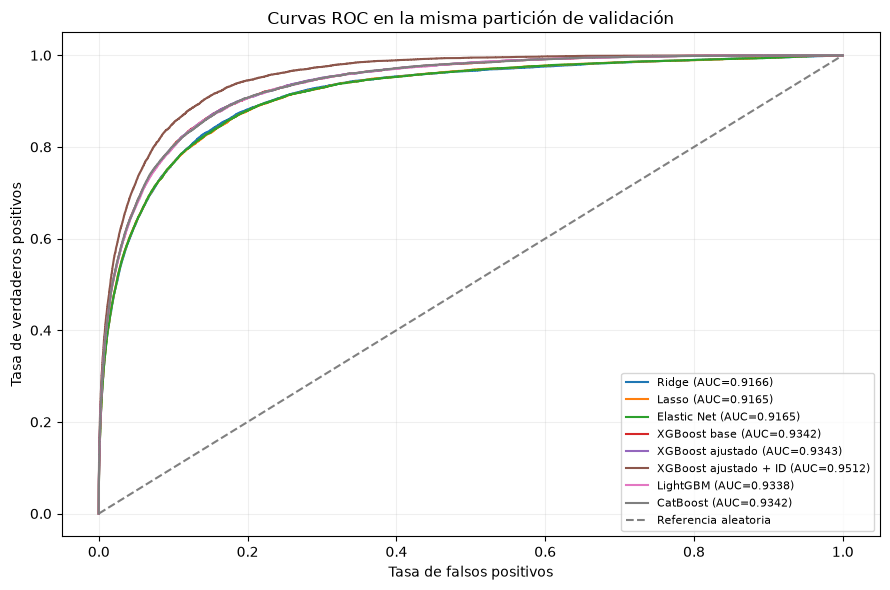

Modelo ganador en validación: XGBoost ajustado + ID
ROC-AUC validación: 0.951229


In [70]:
resultados_auc = pd.DataFrame(resultados_modelos).sort_values(
    "ROC_AUC_validacion", ascending=False
).reset_index(drop=True)
display(resultados_auc)

plt.figure(figsize=(9, 6))
for nombre, scores in puntuaciones_validacion.items():
    fpr, tpr, _ = roc_curve(yva_auc, scores)
    auc_val = roc_auc_score(yva_auc, scores)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC={auc_val:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Referencia aleatoria")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curvas ROC en la misma partición de validación")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

modelo_ganador_auc = str(resultados_auc.loc[0, "Modelo"])
print("Modelo ganador en validación:", modelo_ganador_auc)
print("ROC-AUC validación:", round(float(resultados_auc.loc[0, "ROC_AUC_validacion"]), 6))

### 8. Reentrenar el ganador con todos los registros etiquetados y generar submission

Una vez seleccionado el modelo con la validación local, se vuelve a ajustar con todos los datos etiquetados. El archivo de Kaggle conserva puntuaciones continuas entre 0 y 1; no se aplica un umbral de 0.5, porque ROC-AUC evalúa el orden de las puntuaciones.

In [71]:
entrada_ganador = config_modelos[modelo_ganador_auc]["entrada"]
es_catboost_ganador = config_modelos[modelo_ganador_auc]["es_catboost"]

if entrada_ganador == "con_id":
    X_full_ganador = X_con_id
    X_test_ganador = X_test_con_id
else:
    X_full_ganador = X_sin_id
    X_test_ganador = X_test_sin_id

modelo_ganador = modelos_validacion[modelo_ganador_auc]

if es_catboost_ganador:
    # CatBoost necesita volver a crearse con la mejor cantidad de iteraciones detectada.
    modelo_final = CatBoostClassifier(
        iterations=mejor_iter_cb, depth=8, learning_rate=0.045,
        loss_function="Logloss", eval_metric="AUC", l2_leaf_reg=5.0,
        random_seed=SEMILLA_AUC, thread_count=8,
        verbose=100, allow_writing_files=False
    )
    modelo_final.fit(
        X_full_ganador, y_auc,
        cat_features=[c for c in CAT_AUC if c in X_full_ganador.columns],
        verbose=100
    )
    predicciones_kaggle = modelo_final.predict_proba(X_test_ganador)[:, 1]
else:
    # GridSearchCV se reduce a su mejor pipeline antes del ajuste final.
    if isinstance(modelo_ganador, GridSearchCV):
        modelo_final = clone(modelo_ganador.best_estimator_)
    else:
        modelo_final = clone(modelo_ganador)
    modelo_final.fit(X_full_ganador, y_auc)
    if hasattr(modelo_final, "predict_proba"):
        predicciones_kaggle = modelo_final.predict_proba(X_test_ganador)[:, 1]
    else:
        predicciones_kaggle = np.asarray(modelo_final.predict(X_test_ganador)).reshape(-1)

if not np.isfinite(predicciones_kaggle).all():
    raise ValueError("Se generaron predicciones no finitas; revisa la preparación de las variables.")

submission = pd.DataFrame({
    "ID": prueba["ID"].to_numpy(),
    "Fraude": np.clip(predicciones_kaggle, 0, 1)
})
ruta_submission = os.path.join(ruta_salida, "submission_roc_auc_mejorado.csv")
submission.to_csv(ruta_submission, index=False)

print("Modelo seleccionado por ROC-AUC:", modelo_ganador_auc)
print("Archivo generado:", ruta_submission)
print("Dimensiones del archivo:", submission.shape)
print("Predicciones min/max:", float(submission["Fraude"].min()), float(submission["Fraude"].max()))
display(submission.head())

# Validaciones estructurales del archivo de entrega.
assert list(submission.columns) == ["ID", "Fraude"]
assert len(submission) == len(prueba)
assert submission["ID"].equals(prueba["ID"].reset_index(drop=True))
assert submission["Fraude"].between(0, 1).all()
assert submission["Fraude"].nunique() > 1
print("Validaciones estructurales del archivo superadas.")

Modelo seleccionado por ROC-AUC: XGBoost ajustado + ID
Archivo generado: ..\submissions\submission_roc_auc_mejorado.csv
Dimensiones del archivo: (200027, 2)
Predicciones min/max: 4.3968761019641533e-05 0.9991624355316162


,ID,Fraude
0,9,0.006015
1,11,0.000825
2,19,0.004250
3,20,0.010670
4,22,0.002112


Validaciones estructurales del archivo superadas.


### Cómo interpretar los resultados

- El resultado relevante es `ROC_AUC_validacion`, no el AUC de entrenamiento.
- El resultado público de Kaggle puede ser diferente del AUC local.
- Si CatBoost o LightGBM no aparecen, revisa que estén instalados en el mismo entorno Python que usa el kernel de VS Code; reinícialo y ejecuta el notebook en orden.
- La variante `XGBoost ajustado + ID` comprueba si el identificador ayuda. Si el AUC sube solo en entrenamiento y no en validación, no es una mejora real.
- Guarda el primer envío y usa los siguientes intentos para comparar una modificación a la vez; no cambies muchas cosas simultáneamente.

## Validación cruzada y selección de XGBoost con ID

Se comparan los parámetros actuales y una variante más regularizada mediante validación cruzada estratificada de 3 folds. Los dos modelos usan las mismas variables y el mismo ID. También se evalúa una mezcla de predicciones OOF; la submission final promedia las predicciones de los tres modelos por configuración y aplica el peso seleccionado. La métrica de selección es ROC AUC.

El AUC OOF se estima en los datos de entrenamiento completos. No es directamente comparable con el 0.951229 de la partición 80/20 guardada arriba ni garantiza un AUC determinado en Kaggle.


In [72]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

config_cv = {
    "XGBoost actual": dict(n_estimators=900, max_depth=6, learning_rate=0.035,
        min_child_weight=8, subsample=0.85, colsample_bytree=0.90,
        reg_alpha=0.10, reg_lambda=7.0, gamma=0.0),
    "XGBoost regularizado": dict(n_estimators=1200, max_depth=5, learning_rate=0.030,
        min_child_weight=6, subsample=0.90, colsample_bytree=0.95,
        reg_alpha=0.05, reg_lambda=8.0, gamma=0.0)
}
cv_experimento = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA_AUC)
oof_cv = {nombre: np.zeros(len(y_auc), dtype=np.float32) for nombre in config_cv}
test_cv = {nombre: np.zeros(len(X_test_con_id), dtype=np.float64) for nombre in config_cv}
categoricas_cv = [c for c in CAT_AUC if c in X_con_id.columns]

for fold, (idx_fit, idx_val) in enumerate(cv_experimento.split(X_con_id, y_auc), start=1):
    print(f"Fold {fold}/3")
    for nombre, params in config_cv.items():
        modelo_cv = Pipeline([
            ("preprocesador", crear_preprocesador_auc(X_con_id.iloc[idx_fit], escalar=False)),
            ("modelo", XGBClassifier(
                objective="binary:logistic", eval_metric="auc", tree_method="hist",
                n_jobs=8, random_state=SEMILLA_AUC + fold, verbosity=0, **params
            ))
        ])
        modelo_cv.fit(X_con_id.iloc[idx_fit], y_auc.iloc[idx_fit])
        oof_cv[nombre][idx_val] = modelo_cv.predict_proba(X_con_id.iloc[idx_val])[:, 1]
        test_cv[nombre] += modelo_cv.predict_proba(X_test_con_id)[:, 1] / 3

auc_cv = {nombre: roc_auc_score(y_auc, score) for nombre, score in oof_cv.items()}
pesos_cv = np.linspace(0, 1, 11)
auc_mezclas_cv = {
    float(peso): roc_auc_score(
        y_auc, (1-peso)*oof_cv["XGBoost actual"] + peso*oof_cv["XGBoost regularizado"]
    )
    for peso in pesos_cv
}
peso_ganador_cv = max(auc_mezclas_cv, key=auc_mezclas_cv.get)
if peso_ganador_cv == 0:
    pred_cv = test_cv["XGBoost actual"]
elif peso_ganador_cv == 1:
    pred_cv = test_cv["XGBoost regularizado"]
else:
    pred_cv = (1-peso_ganador_cv)*test_cv["XGBoost actual"] + peso_ganador_cv*test_cv["XGBoost regularizado"]

submission_cv = pd.DataFrame({"ID": prueba["ID"].to_numpy(), "Fraude": np.clip(pred_cv, 0, 1)})
ruta_submission_cv = os.path.join(ruta_salida, "submission_roc_auc_cv.csv")
submission_cv.to_csv(ruta_submission_cv, index=False)
assert submission_cv.shape == (200027, 2)
assert list(submission_cv.columns) == ["ID", "Fraude"]
assert submission_cv["Fraude"].notna().all() and submission_cv["Fraude"].between(0, 1).all()

print("AUC OOF:", {k: round(float(v), 6) for k, v in auc_cv.items()})
print("Pesos probados:", {round(k, 1): round(float(v), 6) for k, v in auc_mezclas_cv.items()})
print("Peso regularizado seleccionado:", peso_ganador_cv)
print("AUC OOF de la mezcla:", round(float(auc_mezclas_cv[peso_ganador_cv]), 6))
print("Submission guardada:", ruta_submission_cv, submission_cv.shape)


Fold 1/3


Fold 2/3


Fold 3/3


AUC OOF: {'XGBoost actual': 0.950648, 'XGBoost regularizado': 0.950698}
Pesos probados: {0.0: 0.950648, 0.1: 0.950685, 0.2: 0.950715, 0.3: 0.950737, 0.4: 0.950753, 0.5: 0.950762, 0.6: 0.950763, 0.7: 0.950758, 0.8: 0.950746, 0.9: 0.950726, 1.0: 0.950698}
Peso regularizado seleccionado: 0.6000000000000001
AUC OOF de la mezcla: 0.950763
Submission guardada: ..\submissions\submission_roc_auc_cv.csv (200027, 2)


## Variante para la segunda submission: bits del ID

Este experimento conserva las variables y parámetros del XGBoost actual, añade los 20 bits del ID y compara ambas entradas en los mismos 3 folds. La celda guarda la mejor mezcla OOF en submission_roc_auc_idbits.csv.


In [73]:
# Variante adicional para la segunda submission: representar el ID en bits.
# Se comparan las mismas particiones y parámetros del modelo actual.
X_bits = X_con_id.copy()
X_test_bits = X_test_con_id.copy()
for bit in range(20):
    nombre = f"ID_bit_{bit}"
    X_bits[nombre] = ((df["ID"].to_numpy(dtype=np.int64) >> bit) & 1).astype("int8")
    X_test_bits[nombre] = ((prueba["ID"].to_numpy(dtype=np.int64) >> bit) & 1).astype("int8")

entradas_bits = {"Actual ID": (X_con_id, X_test_con_id), "ID más bits": (X_bits, X_test_bits)}
oof_bits = {nombre: np.zeros(len(y_auc), dtype=np.float32) for nombre in entradas_bits}
test_bits = {nombre: np.zeros(len(prueba), dtype=np.float64) for nombre in entradas_bits}
cv_bits = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA_AUC)
params_bits = dict(n_estimators=900, max_depth=6, learning_rate=0.035,
    min_child_weight=8, subsample=0.85, colsample_bytree=0.90,
    reg_alpha=0.10, reg_lambda=7.0, gamma=0.0)

for fold, (idx_fit, idx_val) in enumerate(cv_bits.split(X_con_id, y_auc), start=1):
    for nombre, (X_fit_base, X_test_base) in entradas_bits.items():
        cat_cols = [c for c in CAT_AUC if c in X_fit_base.columns]
        num_cols = [c for c in X_fit_base.columns if c not in cat_cols]
        prep = ColumnTransformer([
            ("num", Pipeline([("imputar", SimpleImputer(strategy="median"))]), num_cols),
            ("cat", Pipeline([("imputar", SimpleImputer(strategy="constant", fill_value="SIN_DATO")),
                ("dummies", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
        ], remainder="drop", sparse_threshold=0.3)
        pipe = Pipeline([
            ("preprocesador", prep),
            ("modelo", XGBClassifier(objective="binary:logistic", eval_metric="auc",
                tree_method="hist", n_jobs=8, random_state=SEMILLA_AUC + fold,
                verbosity=0, **params_bits))
        ])
        pipe.fit(X_fit_base.iloc[idx_fit], y_auc.iloc[idx_fit])
        oof_bits[nombre][idx_val] = pipe.predict_proba(X_fit_base.iloc[idx_val])[:, 1]
        test_bits[nombre] += pipe.predict_proba(X_test_base)[:, 1] / 3

auc_bits = {k: roc_auc_score(y_auc, v) for k, v in oof_bits.items()}
pesos_bits = np.linspace(0, 1, 11)
auc_mezclas_bits = {float(w): roc_auc_score(y_auc,
    (1-w)*oof_bits["Actual ID"] + w*oof_bits["ID más bits"]) for w in pesos_bits}
peso_bits = max(auc_mezclas_bits, key=auc_mezclas_bits.get)
pred_bits = (1-peso_bits)*test_bits["Actual ID"] + peso_bits*test_bits["ID más bits"]
submission_bits = pd.DataFrame({"ID": prueba["ID"].to_numpy(), "Fraude": np.clip(pred_bits, 0, 1)})
ruta_bits = os.path.join(ruta_salida, "submission_roc_auc_idbits.csv")
submission_bits.to_csv(ruta_bits, index=False)
assert submission_bits.shape == (200027, 2)
assert list(submission_bits.columns) == ["ID", "Fraude"]
assert submission_bits["Fraude"].notna().all() and submission_bits["Fraude"].between(0, 1).all()
print("AUC OOF:", {k: round(float(v), 6) for k, v in auc_bits.items()})
print("AUC mezclas:", {round(k, 1): round(float(v), 6) for k, v in auc_mezclas_bits.items()})
print("Peso del modelo con bits:", peso_bits)
print("Submission alternativa guardada:", ruta_bits, submission_bits.shape)


AUC OOF: {'Actual ID': 0.950648, 'ID más bits': 0.954088}
AUC mezclas: {0.0: 0.950648, 0.1: 0.951349, 0.2: 0.951925, 0.3: 0.952408, 0.4: 0.952815, 0.5: 0.953157, 0.6: 0.953443, 0.7: 0.953678, 0.8: 0.953863, 0.9: 0.954, 1.0: 0.954088}
Peso del modelo con bits: 1.0
Submission alternativa guardada: ..\submissions\submission_roc_auc_idbits.csv (200027, 2)


## Modelo con bits e intervalos del ID

Esta copia añade la variante que obtuvo el mejor AUC OOF local en la comparación de tres folds. El CSV se genera promediando tres modelos y conserva el orden de IDs del archivo de ejemplo.


In [74]:
# Modelo candidato: XGBoost con los 20 bits del ID y un intervalo categórico de 512 IDs.
# El intervalo se aprende dentro del preprocesamiento de cada fold.
X_512 = X_con_id.copy()
X_test_512 = X_test_con_id.copy()
ids_train = df["ID"].to_numpy(dtype=np.int64)
ids_test = prueba["ID"].to_numpy(dtype=np.int64)
for bit in range(20):
    nombre = f"ID_bit_{bit}"
    X_512[nombre] = ((ids_train >> bit) & 1).astype("int8")
    X_test_512[nombre] = ((ids_test >> bit) & 1).astype("int8")
X_512["ID_bin_512"] = ((ids_train - 1) // 2048).astype(str)
X_test_512["ID_bin_512"] = ((ids_test - 1) // 2048).astype(str)

categoricas_512 = [c for c in CAT_AUC if c in X_512.columns] + ["ID_bin_512"]
numericas_512 = [c for c in X_512.columns if c not in categoricas_512]
parametros_512 = dict(n_estimators=900, max_depth=6, learning_rate=0.035,
    min_child_weight=8, subsample=0.85, colsample_bytree=0.90,
    reg_alpha=0.10, reg_lambda=7.0, gamma=0.0)
cv_512 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA_AUC)
oof_512 = np.zeros(len(y_auc), dtype=np.float32)
pred_test_512 = np.zeros(len(prueba), dtype=np.float64)

for fold, (idx_fit, idx_val) in enumerate(cv_512.split(X_512, y_auc), start=1):
    pre_512 = ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median"))]), numericas_512),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="constant", fill_value="SIN_DATO")),
            ("dummies", OneHotEncoder(handle_unknown="ignore"))]), categoricas_512)
    ], remainder="drop", sparse_threshold=0.3)
    modelo_512 = Pipeline([
        ("preprocesador", pre_512),
        ("modelo", XGBClassifier(objective="binary:logistic", eval_metric="auc",
            tree_method="hist", n_jobs=8, random_state=SEMILLA_AUC + fold,
            verbosity=0, **parametros_512))
    ])
    modelo_512.fit(X_512.iloc[idx_fit], y_auc.iloc[idx_fit])
    oof_512[idx_val] = modelo_512.predict_proba(X_512.iloc[idx_val])[:, 1]
    pred_test_512 += modelo_512.predict_proba(X_test_512)[:, 1] / 3

auc_oof_512 = roc_auc_score(y_auc, oof_512)
submission_512 = pd.DataFrame({
    "ID": prueba["ID"].to_numpy(),
    "Fraude": np.clip(pred_test_512, 0, 1)
})
ruta_submission_512 = os.path.join(ruta_salida, "submission_roc_auc_idbits_512bins.csv")
submission_512.to_csv(ruta_submission_512, index=False)
assert submission_512.shape == (200027, 2)
assert list(submission_512.columns) == ["ID", "Fraude"]
assert submission_512["ID"].equals(prueba["ID"].reset_index(drop=True))
assert submission_512["Fraude"].notna().all()
assert submission_512["Fraude"].between(0, 1).all()
print("AUC OOF (3 folds):", round(float(auc_oof_512), 6))
print("CSV guardado:", ruta_submission_512, submission_512.shape)


AUC OOF (3 folds): 0.954621
CSV guardado: ..\submissions\submission_roc_auc_idbits_512bins.csv (200027, 2)


## Variante de cinco folds

Compara la misma representación de variables con un ensamble de cinco modelos. Cada modelo se entrena con 80% de los datos y las probabilidades de prueba se promedian.


In [75]:
# Variante de cinco folds para bits e intervalos del ID.
# Usa los mismos predictores y parámetros que la versión de tres folds.
X_5f = X_con_id.copy()
X_test_5f = X_test_con_id.copy()
ids_train_5f = df["ID"].to_numpy(dtype=np.int64)
ids_test_5f = prueba["ID"].to_numpy(dtype=np.int64)
for bit in range(20):
    nombre = f"ID_bit_{bit}"
    X_5f[nombre] = ((ids_train_5f >> bit) & 1).astype("int8")
    X_test_5f[nombre] = ((ids_test_5f >> bit) & 1).astype("int8")
X_5f["ID_bin_512"] = ((ids_train_5f - 1) // 2048).astype(str)
X_test_5f["ID_bin_512"] = ((ids_test_5f - 1) // 2048).astype(str)

categoricas_5f = [c for c in CAT_AUC if c in X_5f.columns] + ["ID_bin_512"]
numericas_5f = [c for c in X_5f.columns if c not in categoricas_5f]
parametros_5f = dict(n_estimators=900, max_depth=6, learning_rate=0.035,
    min_child_weight=8, subsample=0.85, colsample_bytree=0.90,
    reg_alpha=0.10, reg_lambda=7.0, gamma=0.0)
cv_5f = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA_AUC)
oof_5f = np.zeros(len(y_auc), dtype=np.float32)
pred_test_5f = np.zeros(len(prueba), dtype=np.float64)

for fold, (idx_fit, idx_val) in enumerate(cv_5f.split(X_5f, y_auc), start=1):
    pre_5f = ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median"))]), numericas_5f),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="constant", fill_value="SIN_DATO")),
            ("dummies", OneHotEncoder(handle_unknown="ignore"))]), categoricas_5f)
    ], remainder="drop", sparse_threshold=0.3)
    modelo_5f = Pipeline([
        ("preprocesador", pre_5f),
        ("modelo", XGBClassifier(objective="binary:logistic", eval_metric="auc",
            tree_method="hist", n_jobs=8, random_state=SEMILLA_AUC + fold,
            verbosity=0, **parametros_5f))
    ])
    modelo_5f.fit(X_5f.iloc[idx_fit], y_auc.iloc[idx_fit])
    oof_5f[idx_val] = modelo_5f.predict_proba(X_5f.iloc[idx_val])[:, 1]
    pred_test_5f += modelo_5f.predict_proba(X_test_5f)[:, 1] / 5

auc_oof_5f = roc_auc_score(y_auc, oof_5f)
submission_5f = pd.DataFrame({
    "ID": prueba["ID"].to_numpy(),
    "Fraude": np.clip(pred_test_5f, 0, 1)
})
ruta_submission_5f = os.path.join(ruta_salida, "submission_roc_auc_idbits_512bins_5fold.csv")
submission_5f.to_csv(ruta_submission_5f, index=False)
assert submission_5f.shape == (200027, 2)
assert list(submission_5f.columns) == ["ID", "Fraude"]
assert submission_5f["ID"].equals(prueba["ID"].reset_index(drop=True))
assert submission_5f["Fraude"].notna().all()
assert submission_5f["Fraude"].between(0, 1).all()
print("AUC OOF (5 folds):", round(float(auc_oof_5f), 6))
print("Submission guardada:", ruta_submission_5f, submission_5f.shape)


AUC OOF (5 folds): 0.955099
Submission guardada: ..\submissions\submission_roc_auc_idbits_512bins_5fold.csv (200027, 2)


## Comparación con 256 intervalos y 5 folds

Esta copia conserva el historial de la versión de 512 intervalos y añade una comparación con 256 categorías usando los mismos folds y parámetros.


In [76]:
# Variante de cinco folds con intervalos del ID de ancho 4096 (256 categorías).
# Mantiene los mismos predictores, folds y parámetros de la versión de 512 categorías.
X_256_5f = X_con_id.copy()
X_test_256_5f = X_test_con_id.copy()
ids_train_256 = df["ID"].to_numpy(dtype=np.int64)
ids_test_256 = prueba["ID"].to_numpy(dtype=np.int64)
for bit in range(20):
    nombre = f"ID_bit_{bit}"
    X_256_5f[nombre] = ((ids_train_256 >> bit) & 1).astype("int8")
    X_test_256_5f[nombre] = ((ids_test_256 >> bit) & 1).astype("int8")
X_256_5f["ID_bin_256"] = ((ids_train_256 - 1) // 4096).astype(str)
X_test_256_5f["ID_bin_256"] = ((ids_test_256 - 1) // 4096).astype(str)

categoricas_256_5f = [c for c in CAT_AUC if c in X_256_5f.columns] + ["ID_bin_256"]
numericas_256_5f = [c for c in X_256_5f.columns if c not in categoricas_256_5f]
parametros_256_5f = dict(n_estimators=900, max_depth=6, learning_rate=0.035,
    min_child_weight=8, subsample=0.85, colsample_bytree=0.90,
    reg_alpha=0.10, reg_lambda=7.0, gamma=0.0)
cv_256_5f = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA_AUC)
oof_256_5f = np.zeros(len(y_auc), dtype=np.float32)
pred_test_256_5f = np.zeros(len(prueba), dtype=np.float64)

for fold, (idx_fit, idx_val) in enumerate(cv_256_5f.split(X_256_5f, y_auc), start=1):
    pre_256_5f = ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median"))]), numericas_256_5f),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="constant", fill_value="SIN_DATO")),
            ("dummies", OneHotEncoder(handle_unknown="ignore"))]), categoricas_256_5f)
    ], remainder="drop", sparse_threshold=0.3)
    modelo_256_5f = Pipeline([
        ("preprocesador", pre_256_5f),
        ("modelo", XGBClassifier(objective="binary:logistic", eval_metric="auc",
            tree_method="hist", n_jobs=8, random_state=SEMILLA_AUC + fold,
            verbosity=0, **parametros_256_5f))
    ])
    modelo_256_5f.fit(X_256_5f.iloc[idx_fit], y_auc.iloc[idx_fit])
    oof_256_5f[idx_val] = modelo_256_5f.predict_proba(X_256_5f.iloc[idx_val])[:, 1]
    pred_test_256_5f += modelo_256_5f.predict_proba(X_test_256_5f)[:, 1] / 5

auc_oof_256_5f = roc_auc_score(y_auc, oof_256_5f)
submission_256_5f = pd.DataFrame({
    "ID": prueba["ID"].to_numpy(),
    "Fraude": np.clip(pred_test_256_5f, 0, 1)
})
ruta_submission_256_5f = os.path.join(ruta_salida, "submission_roc_auc_idbits_256bins_5fold.csv")
submission_256_5f.to_csv(ruta_submission_256_5f, index=False)
assert submission_256_5f.shape == (200027, 2)
assert list(submission_256_5f.columns) == ["ID", "Fraude"]
assert submission_256_5f["ID"].equals(prueba["ID"].reset_index(drop=True))
assert submission_256_5f["Fraude"].notna().all()
assert submission_256_5f["Fraude"].between(0, 1).all()
print("AUC OOF (5 folds):", round(float(auc_oof_256_5f), 6))
print("AUC OOF 512 intervalos, 5 folds: 0.955099")
print("Submission guardada:", ruta_submission_256_5f, submission_256_5f.shape)


AUC OOF (5 folds): 0.955219
AUC OOF 512 intervalos, 5 folds: 0.955099
Submission guardada: ..\submissions\submission_roc_auc_idbits_256bins_5fold.csv (200027, 2)
